# 04 · Results: what the data show

**Purpose.** Fit the annual daytime low on rooftop photovoltaic (PV) capacity and on the year and draw Fig. 2; draw Fig. 3, the daily daytime low against solar exposure; and save three checks that back sentences in the paper.

**Approximate runtime.** Under 30 seconds.

**Paper section served.** IV-A Results: what the data show.

**Inputs**

- `data/interim/network_30min.parquet` from notebook 01.
- `data/interim/pv_annual.parquet` and `weather_daily.parquet` from notebook 02.

**Paper artifacts**

- `results/figures/fig2` (PNG at 600 dpi and PDF) and `results/tables/fig2_data.csv`: Fig. 2, the annual daytime low against PV capacity, and its eleven points.
- `results/tables/table_pv_fit.csv`: the straight-line fit of the annual daytime low on PV capacity and on the year. The line in Fig. 2 is its first row.
- `results/figures/fig3` (PNG and PDF) and `results/tables/fig3_fits.csv`: Fig. 3, the daily daytime low against solar exposure for three years, and its three lines.

**Supporting checks** (`results/checks`)

- `check_annual_minima.csv`: each year's minimum, with its date, time and day type, and the year's two lows.
- `check_low_hours.csv`: the share of each year's lowest 1% of half hours that fall in the daytime window and in the overnight window.
- `check_trough_windows.csv`: how often the day's minimum falls outside both trough windows.

**Main process**

1. Set up.
2. Fig. 2: the annual daytime low against PV capacity.
3. Fig. 3: the daily daytime low against solar exposure.
4. Check: each year's minimum.
5. Check: when the lowest half hours occur.
6. Check: do the two trough windows catch the daily minimum?
7. Result.

Earlier figures made from the same data (the heat map of the lowest half hours, the low end of the load duration curve, and the two-panel figure of sunshine and temperature) are in `exploration/01_conference/A2_superseded_figures.ipynb`.

## 1. Set up

In [1]:
import pandas as pd

from pynmdf import plots, targets
from pynmdf.config import load_config

cfg = load_config()
interim, figures, tables, checks = (
    cfg["dirs"][key] for key in ("interim", "figures", "tables", "checks")
)
windows = cfg["targets"]["troughs"]
selected_years = cfg["figures"]["selected_years"]
plots.set_style()

pd.set_option("display.width", 220, "display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)
total = pd.read_parquet(interim / "network_30min.parquet")["total_mw"]
weather = pd.read_parquet(interim / "weather_daily.parquet")
capacity = pd.read_parquet(interim / "pv_annual.parquet")["kwp"]

## 2. Fig. 2: the annual daytime low against PV capacity

Two straight lines are fitted to the eleven annual daytime lows of 2015 to 2025: one on PV capacity, one on the year. PV capacity is the published network total at 30 June of each year, in MW. Each line is fitted on its own, so the two can be compared: which single quantity tracks the daytime low more closely over the decade.

The first table is the data, which are the points of Fig. 2. The second gives each line's slope (MW of daytime low per MW of PV capacity, or per year), its intercept, R-squared and RMSE. RMSE is the root mean squared residual of the eleven points, in MW, with no adjustment for the two fitted parameters. These are fits to annual values in hindsight, not forecasts.

In [2]:
annual_lows = targets.annual_window_lows(total, windows)
points = pd.DataFrame(
    {"pv_mw": capacity / 1000, "daytime_low_mw": annual_lows["daytime_low_mw"]}
).rename_axis("year")
points.to_csv(tables / "fig2_data.csv")

pv_fit = targets.line_fits(points.assign(year=points.index), "daytime_low_mw", ["pv_mw", "year"])
pv_fit.to_csv(tables / "table_pv_fit.csv")
points.T.round()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pv_mw,230.0,287.0,346.0,449.0,620.0,780.0,"1,050.0","1,291.0","1,563.0","1,882.0","2,084.0"
daytime_low_mw,"1,833.0","1,891.0","1,888.0","1,902.0","1,759.0","1,671.0","1,357.0","1,458.0","1,080.0","1,019.0",880.0


In [3]:
print(pv_fit.to_string(float_format="{:,.3f}".format))

             slope   intercept  r_squared    rmse  points
fitted_on                                                
pv_mw       -0.570   2,070.131      0.958  75.080      11
year      -108.773 221,243.283      0.879 127.776      11


Fig. 2 plots the eleven points, each labelled with its year, and the line fitted on PV capacity, with its R-squared.

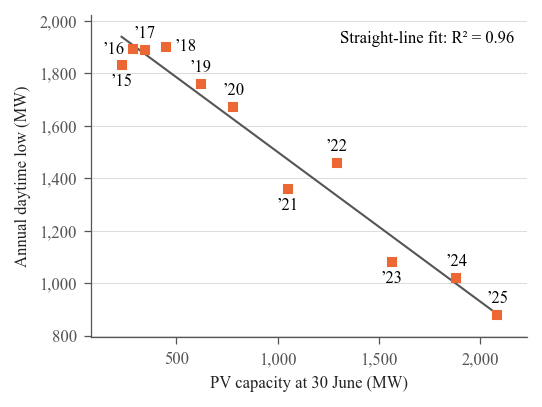

In [4]:
figure = plots.daytime_low_against_pv(points, pv_fit.loc["pv_mw"])
plots.save_figure(figure, figures, "fig2")

## 3. Fig. 3: the daily daytime low against solar exposure

Each point is one day, for three years. Sunshine acts on the midday dip, so each day's **daytime low** is plotted against that day's solar exposure, with a least-squares line per year. Only days on which both trough windows are complete are used.

The table gives the three lines, so the slopes can be quoted. A slope is in MW per MJ/m².

year,2015,2020,2025
slope,0.6,-6.6,-35.4
intercept,"2,578.7","2,477.0","2,540.8"
x_min,2.7,1.3,2.6
x_max,33.1,31.7,31.9
days,358.0,347.0,360.0


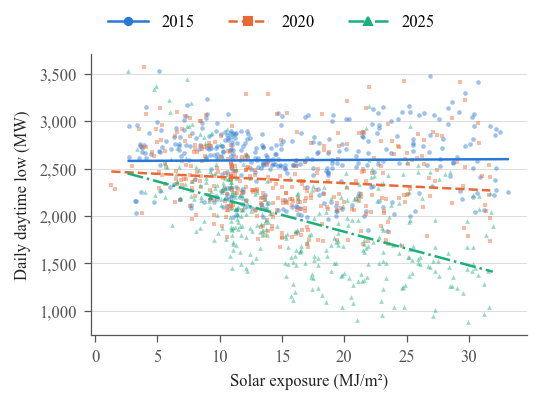

In [5]:
daily = pd.concat(
    [targets.daily_troughs(total, windows)["daytime"], weather["solar"]], axis=1, join="inner"
)
solar_fits = targets.yearly_line_fits(daily, "solar", "daytime", selected_years)
solar_fits.to_csv(tables / "fig3_fits.csv")

figure = plots.daytime_low_against_solar(daily, solar_fits)
plots.save_figure(figure, figures, "fig3")
solar_fits.T

## 4. Check: each year's minimum

For each year: the minimum, the date, the time its half hour ended, the day of the week, the public holiday if it was one, and that day's solar exposure and maximum temperature at Sydney Airport. The last two columns give the year's overnight low (00:00 to 06:00) and daytime low (09:00 to 17:00); the minimum is the lower of the two.

The paper states when the minimum fell and on what kind of day; this table is where those statements come from.

In [6]:
annual_minima = targets.annual_minimum_table(
    total, weather, cfg["calendar"]["holiday_subdivision"], windows
)
annual_minima.to_csv(checks / "check_annual_minima.csv")
annual_minima

,min_mw,date,time,day,public_holiday,solar_mj_m2,tmax_c,overnight_low_mw,daytime_low_mw
year,,,,,,,,,
2015,"1,368.1",2015-04-05,04:30,Sun,Easter Sunday,16.2,23.2,"1,368.1","1,832.6"
2016,"1,432.6",2016-04-24,05:00,Sun,,14.3,22.0,"1,432.6","1,891.4"
2017,"1,474.3",2017-04-17,04:30,Mon,Easter Monday,14.2,23.7,"1,474.3","1,888.2"
2018,"1,495.1",2018-04-29,05:00,Sun,,13.4,20.2,"1,495.1","1,901.7"
2019,"1,473.0",2019-11-10,05:00,Sun,,28.6,23.9,"1,473.0","1,759.2"
2020,"1,429.5",2020-04-12,05:00,Sun,Easter Sunday,17.1,20.5,"1,429.5","1,671.0"
2021,"1,357.4",2021-10-17,14:30,Sun,,25.7,21.5,"1,387.6","1,357.4"
2022,"1,428.3",2022-04-17,05:00,Sun,Easter Sunday,14.9,24.7,"1,428.3","1,457.9"
2023,"1,080.0",2023-10-29,13:00,Sun,,27.4,26.0,"1,393.2","1,080.0"


## 5. Check: when the lowest half hours occur

Take the lowest 1% of each year's valid half hours (about 170 of them) and count the share that start inside the daytime window (09:00 to 17:00), inside the overnight window (00:00 to 06:00), and outside both. Times are local clock time.

A single lowest half hour could fall in the daytime by chance. This check shows whether the whole low end of the year has moved.

In [7]:
lowest = targets.lowest_intervals(total, cfg["figures"]["low_share"])
low_hours = targets.low_window_shares(targets.low_hour_shares(lowest), windows)
low_hours.to_csv(checks / "check_low_hours.csv")
low_hours.T.round()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
overnight_pct,100.0,96.0,98.0,97.0,98.0,98.0,79.0,69.0,0.0,0.0,0.0
daytime_pct,0.0,0.0,0.0,0.0,0.0,0.0,19.0,27.0,97.0,99.0,100.0
other_pct,0.0,4.0,2.0,3.0,2.0,2.0,2.0,4.0,3.0,1.0,0.0


## 6. Check: do the two trough windows catch the daily minimum?

The daily models fit an overnight trough (00:00 to 06:00) and a daytime trough (09:00 to 17:00) separately and take the lower. That only works if the day's true minimum falls inside one of the two windows. This check counts the days on which it does not, and shows how often the daytime trough is the lower one.

In [8]:
troughs = targets.daily_troughs(total, windows)
both = pd.concat([targets.daily_minimum(total), troughs], axis=1).dropna()
lower_trough = both[["overnight", "daytime"]].min(axis=1)
miss = lower_trough - both["min_mw"]  # how far the true minimum sits below both troughs
year = both.index.year

window_check = pd.DataFrame(
    {
        "complete_days": both.groupby(year).size(),
        "minimum_outside_both_pct": 100 * (miss > 1e-9).groupby(year).mean(),
        "largest_miss_mw": miss.groupby(year).max(),
        "daytime_lower_pct": 100 * (both["daytime"] < both["overnight"]).groupby(year).mean(),
    }
).rename_axis("year")
window_check.to_csv(checks / "check_trough_windows.csv")
window_check.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
complete_days,357.0,361.0,360.0,365.0,353.0,347.0,331.0,352.0,342.0,309.0,359.0
minimum_outside_both_pct,0.0,0.3,0.6,0.0,0.0,0.0,0.0,0.0,0.3,0.3,0.3
largest_miss_mw,0.0,398.7,40.4,0.0,0.0,0.0,0.0,0.0,0.4,31.9,14.2
daytime_lower_pct,0.0,0.0,0.0,0.0,0.0,0.0,0.9,3.4,17.8,26.2,32.9


## 7. Result

The numbers behind the items of this notebook, in one place.

In [9]:
print("Annual daytime low fitted on PV capacity and on the year (R-squared; RMSE in MW):")
print(pv_fit[["r_squared", "rmse"]].round({"r_squared": 3, "rmse": 1}).T.to_dict())
print()
print("Slope of the daily daytime low on solar exposure (MW per MJ/m2):")
print(solar_fits["slope"].round(1).to_dict())
print()
print("Share of each year's lowest 1% of half hours in the daytime window (%):")
print(low_hours["daytime_pct"].round().astype(int).to_dict())
print()
worst = window_check["minimum_outside_both_pct"].max()
print(f"Days whose minimum falls outside both trough windows: {worst:.1f}% at most in any year")
annual_minima[["min_mw", "date", "time", "day", "overnight_low_mw", "daytime_low_mw"]]

Annual daytime low fitted on PV capacity and on the year (R-squared; RMSE in MW):
{'pv_mw': {'r_squared': 0.958, 'rmse': 75.1}, 'year': {'r_squared': 0.879, 'rmse': 127.8}}

Slope of the daily daytime low on solar exposure (MW per MJ/m2):
{2015: 0.6, 2020: -6.6, 2025: -35.4}

Share of each year's lowest 1% of half hours in the daytime window (%):
{2015: 0, 2016: 0, 2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 19, 2022: 27, 2023: 97, 2024: 99, 2025: 100}

Days whose minimum falls outside both trough windows: 0.6% at most in any year


,min_mw,date,time,day,overnight_low_mw,daytime_low_mw
year,,,,,,
2015,"1,368.1",2015-04-05,04:30,Sun,"1,368.1","1,832.6"
2016,"1,432.6",2016-04-24,05:00,Sun,"1,432.6","1,891.4"
2017,"1,474.3",2017-04-17,04:30,Mon,"1,474.3","1,888.2"
2018,"1,495.1",2018-04-29,05:00,Sun,"1,495.1","1,901.7"
2019,"1,473.0",2019-11-10,05:00,Sun,"1,473.0","1,759.2"
2020,"1,429.5",2020-04-12,05:00,Sun,"1,429.5","1,671.0"
2021,"1,357.4",2021-10-17,14:30,Sun,"1,387.6","1,357.4"
2022,"1,428.3",2022-04-17,05:00,Sun,"1,428.3","1,457.9"
2023,"1,080.0",2023-10-29,13:00,Sun,"1,393.2","1,080.0"
